In [ ]:
import pandas as pd

data = {
    'Record': ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7'],
    'A': [1.0, 1.5, 3.0, 5.0, 3.5, 4.5, 3.5],
    'B': [1.0, 2.0, 4.0, 7.0, 5.0, 5.0, 4.5]
}

df = pd.DataFrame(data)

print(df)

  Record    A    B
0     R1  1.0  1.0
1     R2  1.5  2.0
2     R3  3.0  4.0
3     R4  5.0  7.0
4     R5  3.5  5.0
5     R6  4.5  5.0
6     R7  3.5  4.5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

In [ ]:
X = df[['A', 'B']].values

distance_matrix = np.zeros((len(X), len(X)))

for i in range(len(X)):
    for j in range(len(X)):
        distance_matrix[i, j] = np.sqrt(np.sum((X[i] - X[j]) ** 2))

distance_df = pd.DataFrame(
    distance_matrix,
    index=df['Record'],
    columns=df['Record']
)

print("Initial Distance Matrix:")
print(distance_df.round(3))

Initial Distance Matrix:
Record     R1     R2     R3     R4     R5     R6     R7
Record                                                 
R1      0.000  1.118  3.606  7.211  4.717  5.315  4.301
R2      1.118  0.000  2.500  6.103  3.606  4.243  3.202
R3      3.606  2.500  0.000  3.606  1.118  1.803  0.707
R4      7.211  6.103  3.606  0.000  2.500  2.062  2.915
R5      4.717  3.606  1.118  2.500  0.000  1.000  0.500
R6      5.315  4.243  1.803  2.062  1.000  0.000  1.118
R7      4.301  3.202  0.707  2.915  0.500  1.118  0.000


In [ ]:
print("Iteration 1")
print("Clusters merged: R5 + R7")
print("Minimum distance: 0.500")

Iteration 1
Clusters merged: R5 + R7
Minimum distance: 0.500


In [ ]:
clusters = ['R1', 'R2', 'R3', 'R4', 'R6', '{R5,R7}']

matrix = [
    [0,     1.118, 3.606, 7.211, 5.315, 4.301],
    [1.118, 0,     2.500, 6.103, 4.243, 3.202],
    [3.606, 2.500, 0,     3.606, 1.803, 0.707],
    [7.211, 6.103, 3.606, 0,     2.062, 2.500],
    [5.315, 4.243, 1.803, 2.062, 0,     1.000],
    [4.301, 3.202, 0.707, 2.500, 1.000, 0]
]

distance_1 = pd.DataFrame(
    matrix,
    index=clusters,
    columns=clusters
)

print(distance_1.round(3))

            R1     R2     R3     R4     R6  {R5,R7}
R1       0.000  1.118  3.606  7.211  5.315    4.301
R2       1.118  0.000  2.500  6.103  4.243    3.202
R3       3.606  2.500  0.000  3.606  1.803    0.707
R4       7.211  6.103  3.606  0.000  2.062    2.500
R6       5.315  4.243  1.803  2.062  0.000    1.000
{R5,R7}  4.301  3.202  0.707  2.500  1.000    0.000


In [ ]:
print("Iteration 2")
print("Clusters merged: R3 + {R5,R7}")
print("Minimum distance: 0.707")

Iteration 2
Clusters merged: R3 + {R5,R7}
Minimum distance: 0.707


In [ ]:
clusters = ['R1', 'R2', 'R4', 'R6', '{R3,R5,R7}']

matrix = [
    [0,     1.118, 7.211, 5.315, 3.606],
    [1.118, 0,     6.103, 4.243, 2.500],
    [7.211, 6.103, 0,     2.062, 2.500],
    [5.315, 4.243, 2.062, 0,     1.000],
    [3.606, 2.500, 2.500, 1.000, 0]
]

distance_2 = pd.DataFrame(
    matrix,
    index=clusters,
    columns=clusters
)

print(distance_2.round(3))

               R1     R2     R4     R6  {R3,R5,R7}
R1          0.000  1.118  7.211  5.315       3.606
R2          1.118  0.000  6.103  4.243       2.500
R4          7.211  6.103  0.000  2.062       2.500
R6          5.315  4.243  2.062  0.000       1.000
{R3,R5,R7}  3.606  2.500  2.500  1.000       0.000


In [ ]:
print("Iteration 3")
print("Clusters merged: R6 + {R3,R5,R7}")
print("Minimum distance: 1.000")

Iteration 3
Clusters merged: R6 + {R3,R5,R7}
Minimum distance: 1.000


In [ ]:
clusters = ['R1', 'R2', 'R4', '{R3,R5,R6,R7}']

matrix = [
    [0,     1.118, 7.211, 3.606],
    [1.118, 0,     6.103, 2.500],
    [7.211, 6.103, 0,     2.062],
    [3.606, 2.500, 2.062, 0]
]

distance_3 = pd.DataFrame(
    matrix,
    index=clusters,
    columns=clusters
)

print(distance_3.round(3))

                  R1     R2     R4  {R3,R5,R6,R7}
R1             0.000  1.118  7.211          3.606
R2             1.118  0.000  6.103          2.500
R4             7.211  6.103  0.000          2.062
{R3,R5,R6,R7}  3.606  2.500  2.062          0.000


In [ ]:
print("Iteration 4")
print("Clusters merged: R1 + R2")
print("Minimum distance: 1.118")

Iteration 4
Clusters merged: R1 + R2
Minimum distance: 1.118


In [ ]:
clusters = ['{R1,R2}', 'R4', '{R3,R5,R6,R7}']

matrix = [
    [0,     6.103, 2.500],
    [6.103, 0,     2.062],
    [2.500, 2.062, 0]
]

distance_4 = pd.DataFrame(
    matrix,
    index=clusters,
    columns=clusters
)

print(distance_4.round(3))

               {R1,R2}     R4  {R3,R5,R6,R7}
{R1,R2}          0.000  6.103          2.500
R4               6.103  0.000          2.062
{R3,R5,R6,R7}    2.500  2.062          0.000


In [ ]:
print("Iteration 5")
print("Clusters merged: R4 + {R3,R5,R6,R7}")
print("Minimum distance: 2.062")

Iteration 5
Clusters merged: R4 + {R3,R5,R6,R7}
Minimum distance: 2.062


In [ ]:
clusters = ['{R1,R2}', '{R3,R4,R5,R6,R7}']

matrix = [
    [0,     2.500],
    [2.500, 0]
]

distance_5 = pd.DataFrame(
    matrix,
    index=clusters,
    columns=clusters
)

print(distance_5.round(3))

                  {R1,R2}  {R3,R4,R5,R6,R7}
{R1,R2}               0.0               2.5
{R3,R4,R5,R6,R7}      2.5               0.0


In [ ]:
print("Iteration 6")
print("Clusters merged: {R1,R2} + {R3,R4,R5,R6,R7}")
print("Distance: 2.500")

Iteration 6
Clusters merged: {R1,R2} + {R3,R4,R5,R6,R7}
Distance: 2.500


In [ ]:
result = pd.DataFrame({
    'Iteration': [1, 2, 3, 4, 5, 6],

    'Clusters Merged': [
        'R5 + R7',
        'R3 + {R5,R7}',
        'R6 + {R3,R5,R7}',
        'R1 + R2',
        'R4 + {R3,R5,R6,R7}',
        '{R1,R2} + {R3,R4,R5,R6,R7}'
    ],

    'Distance': [
        0.500,
        0.707,
        1.000,
        1.118,
        2.062,
        2.500
    ]
})

print(result.to_string(index=False))

 Iteration            Clusters Merged  Distance
         1                    R5 + R7     0.500
         2               R3 + {R5,R7}     0.707
         3            R6 + {R3,R5,R7}     1.000
         4                    R1 + R2     1.118
         5         R4 + {R3,R5,R6,R7}     2.062
         6 {R1,R2} + {R3,R4,R5,R6,R7}     2.500


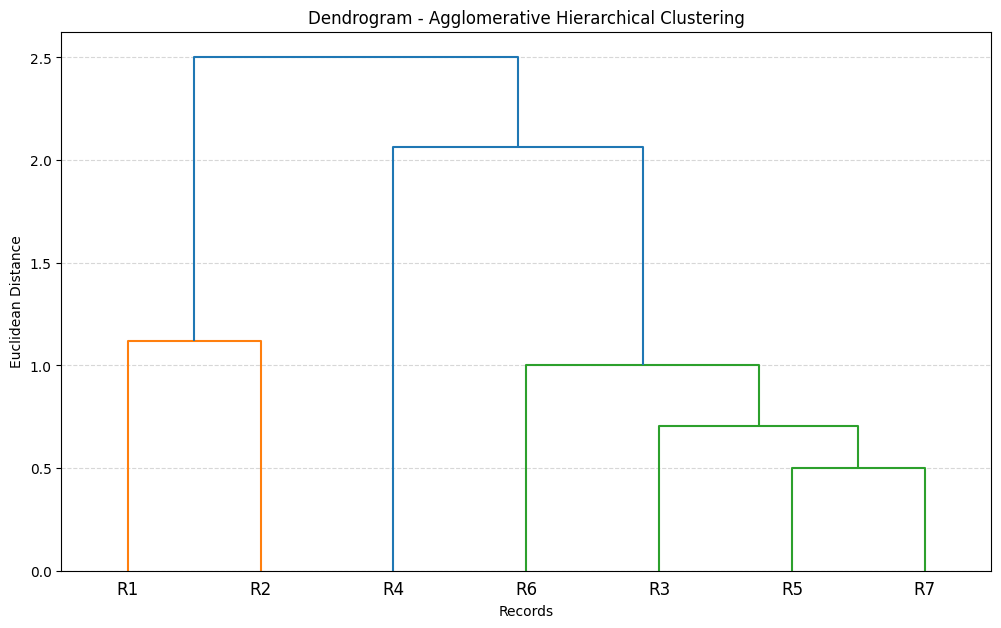

In [ ]:
Z = np.array([
    [4, 6, 0.500, 2],      # R5 + R7
    [2, 7, 0.707, 3],      # R3 + {R5,R7}
    [5, 8, 1.000, 4],      # R6 + {R3,R5,R7}
    [0, 1, 1.118, 2],      # R1 + R2
    [3, 9, 2.062, 5],      # R4 + {R3,R5,R6,R7}
    [10, 11, 2.500, 7]     # Final merge
])

plt.figure(figsize=(12, 7))

dendrogram(
    Z,
    labels=['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7']
)

plt.title('Dendrogram - Agglomerative Hierarchical Clustering')
plt.xlabel('Records')
plt.ylabel('Euclidean Distance')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()